ссылка на notebook
https://cloud.mail.ru/public/Lkgd/pK6Ygku7k

In [9]:
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_squared_error, roc_auc_score, average_precision_score,
                             log_loss, brier_score_loss, precision_score, recall_score)


RANDOM_STATE = 13
np.random.seed(RANDOM_STATE)


# DecisionTree

| Достоинства | Недостатки |
|---|---|
| Автоматически обнаруживает нелинейности и взаимодействия.  | Глубокое дерево **нестабильно**: небольшое изменение выборки может полностью изменить разбиения.|


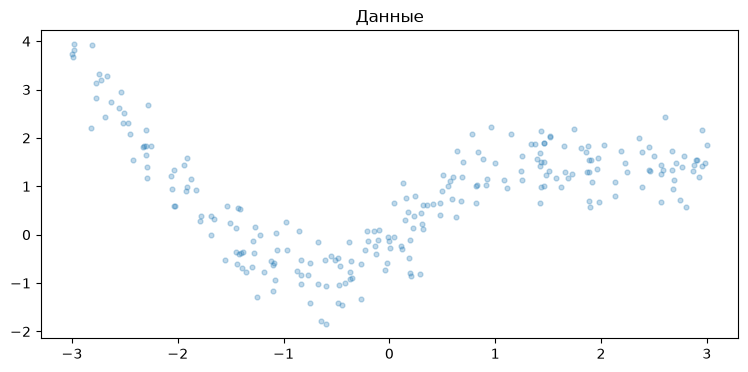

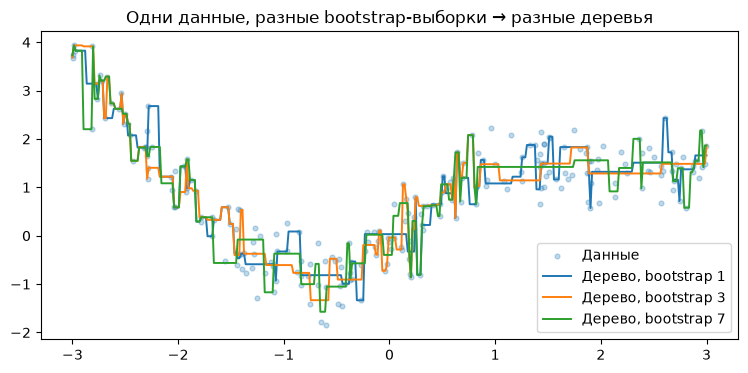

In [10]:
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(RANDOM_STATE)
x = rng.uniform(-3, 3, 240)
y = np.sin(1.5*x) + .3*x**2 + rng.normal(0, .45, len(x))


f, ax = plt.subplots(figsize=(9, 4))
ax.set_title("Данные")
ax.scatter(x, y, s=12, alpha=.28, label='Данные')
plt.show()


grid = np.linspace(-3, 3, 400).reshape(-1, 1)

f, ax = plt.subplots(figsize=(9, 4))
ax.scatter(x, y, s=12, alpha=.28, label='Данные')
for seed in (1, 3, 7):
    ids = np.random.default_rng(seed).choice(len(x), len(x), replace=True)
    tree = DecisionTreeRegressor(max_depth=8, random_state=seed).fit(x[ids, None], y[ids])
    ax.plot(grid[:,0], tree.predict(grid), linewidth=1.4, label=f'Дерево, bootstrap {seed}')
ax.legend()
ax.set_title('Одни данные, разные bootstrap-выборки → разные деревья')
plt.show()

## 2. Bagging (Bootstrap Aggregating)

Строим $B$ деревьев на bootstrap-выборках и усредняем:

$$\hat f_{bag}(x)=\frac1B\sum_{b=1}^{B}\hat f_b(x).$$

Если для фиксированного $x$ дисперсия ошибки каждого дерева равна $\sigma^2$, а попарная корреляция ошибок равна $\rho$, то

$$\operatorname{Var}\left(\frac1B\sum_b\hat f_b(x)\right)=\sigma^2\left(\rho+\frac{1-\rho}{B}\right).$$

Рост $B$ уменьшает некоррелированную часть variance. Если $\rho\approx1$, добавление деревьев почти не помогает. 



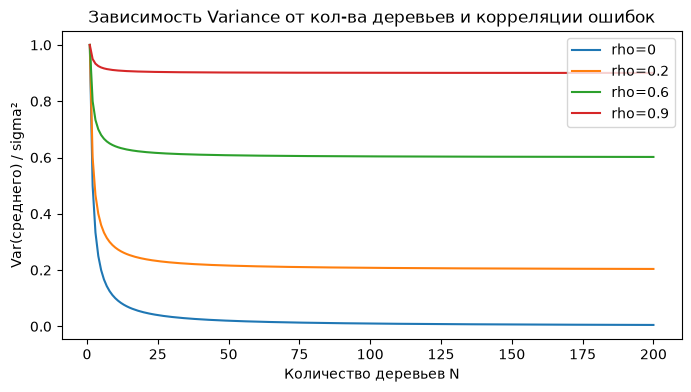

In [ ]:
N = np.arange(1, 201)

plt.figure(figsize=(8, 4))
for rho in [0, .2, .6, .9]:
    plt.plot(N, rho + (1-rho)/N, label=f'rho={rho}')
plt.xlabel('Количество деревьев N')
plt.ylabel('Var(среднего) / sigma²')
plt.title('Зависимость Variance от кол-ва деревьев и корреляции ошибок')
plt.legend()
plt.show()

# Дерево vs Bagging

## OOB

**OOB:** каждое дерево не видит примерно 36.8% уникальных обучающих наблюдений (в среднем); их можно использовать для внутренней оценки качества. 

OOB **не заменяет** независимый test 

**Для временных рядов** обычная OOB-оценка **не заменяет* временную валидацию.

In [12]:
# Сравнение одного дерева и Bagging
X_train, X_test, y_train, y_test = \
    train_test_split(x.reshape(-1, 1), y, test_size=.3, random_state=42)

models = {
    'Decision Tree': DecisionTreeRegressor(max_depth=None, random_state=42),
    'Bagging (100)': BaggingRegressor(estimator=DecisionTreeRegressor(), 
                                      n_estimators=100,
                                     bootstrap=True, 
                                     oob_score=True, 
                                     random_state=42, 
                                     n_jobs=-1)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'train RMSE', 
            round(np.sqrt(mean_squared_error(y_train,model.predict(X_train))),3),
          '| test RMSE', round(np.sqrt(mean_squared_error(y_test,model.predict(X_test))),3),
          '| OOB score', round(model.oob_score_,3) if hasattr(model,'oob_score_') else '—')

Decision Tree train RMSE 0.0 | test RMSE 0.613 | OOB score —
Bagging (100) train RMSE 0.213 | test RMSE 0.501 | OOB score 0.784


In [13]:
from mlxtend.evaluate import bias_variance_decomp

_, avg_bias, avg_var = bias_variance_decomp(models['Decision Tree'], X_train, y_train,\
        X_test, y_test,\
        loss = 'mse', random_seed = 2)

print(f'Decision Tree: bias {avg_bias}, var {avg_var} all {_}')

_, avg_bias, avg_var = bias_variance_decomp(models['Bagging (100)'], X_train, y_train,\
        X_test, y_test,\
        loss = 'mse', random_seed = 2)

print(f'Bagging (100): bias {avg_bias}, var {avg_var} all {_}')



Decision Tree: bias 0.2516537433511761, var 0.11791904229307022 all 0.3695727856442461
Bagging (100): bias 0.21981970191092456, var 0.06819229612844191 all 0.2880119980393664


## 3. Random Forest

Bagging уменьшает variance усреднением. Но если сильный признак выбирается почти в каждом дереве, то деревья остаются похожими.

Для снижения корреляции **Random Forest** дополнительно ограничивает множество кандидатов для split при каждом узле (`max_features`). 

**Плюсы:** 
 - надежный baseline; 
 - учитывает нелинейности и взаимодействия; 
 - относительно простая настройка.

**Минусы:** 
- может уступать бустингу по качеству; 
- глубокие леса потребляют память; 
- увеличение числа деревьев не гарантирует постоянного улучшения; 
- Не экстраполирует за диапазон обучающих $y$; 
- при разреженных очень высокоразмерных данных линейный baseline иногда выгоднее.

##  Основные методы RandomForestClassifier

| Метод	| Что делает|
|---|---|
| fit(X, y)	| Обучает случайный лес|
| predict(X)	| Предсказывает классы|
| predict_proba(X)	| Возвращает вероятности классов|
| predict_log_proba(X)	| Возвращает логарифмы вероятностей классов|
| score(X, y)	| Вычисляет Accuracy/коэффициент детерминации R²|
| apply(X)	| Возвращает индексы листьев, в которые попали объекты в каждом дереве|
| decision_path(X)	|Показывает пути объектов через узлы всех деревьев|
| get_params()	| Возвращает гиперпараметры модели|
| set_params(**params)	| Изменяет гиперпараметры|




| Атрибут	| Что возвращает|
|---|---|
|estimators_ |	Список обученных деревьев DecisionTreeClassifier |
|feature_importances_ |	Важность каждого признака по суммарному уменьшению impurity |
|classes_ |	Список классов |
|n_classes_ |	Количество классов |
|n_features_in_ |	Количество входных признаков |
|feature_names_in_ |	Названия признаков, если модель обучена на DataFrame с подходящими строковыми именами колонок |
|oob_score_ |	OOB-оценка качества, если включена |
|oob_decision_function_ |	OOB-оценки вероятностей классов для обучающих объектов |
|estimators_samples_ |	Индексы объектов, выбранных для обучения каждого дерева |
|max_samples |	Доля или количество обучающих объектов для одного bootstrap-сэмпла (гиперпараметр) |


Атрибуты с окончанием _ обычно появляются после fit().

In [14]:
noise = np.random.default_rng(11).normal(size=(len(x), 12))
X_many = np.column_stack([x**2, np.sin(x),  noise])

Xt, Xv, yt, yv = train_test_split(X_many, y, test_size=.30, random_state=42)
rows = []

for max_features in [1.0, .5, .25]:
    rf = RandomForestRegressor(n_estimators=120, max_features=max_features,
                               min_samples_leaf=2, random_state=42, n_jobs=-1, oob_score=True)
    rf.fit(Xt,yt)
    rows.append({'max_features':max_features,
                 'train_RMSE':np.sqrt(mean_squared_error(yt,rf.predict(Xt))),
                 'test_RMSE':np.sqrt(mean_squared_error(yv,rf.predict(Xv))),
                 'OOB_R2':rf.oob_score_})
display(pd.DataFrame(rows).round(3))

,max_features,train_RMSE,test_RMSE,OOB_R2
0,1.00,0.243,0.461,0.783
1,0.50,0.277,0.474,0.738
2,0.25,0.365,0.570,0.594


In [10]:
rf.estimators_[0].predict(Xv)

array([ 7.05506775e-01,  1.36548655e-03,  1.20498714e+00,  3.63472481e-01,
        1.62100337e+00,  1.55183209e-01, -5.99624161e-01,  2.74036673e-01,
        6.23536865e-01, -9.95415821e-01,  1.54194681e-01,  2.74036673e-01,
        2.74036673e-01,  1.95768613e+00,  1.11504674e+00,  3.63472481e-01,
       -9.95415821e-01, -5.26809690e-01,  2.68011267e+00,  1.95768613e+00,
       -9.95415821e-01,  1.11504674e+00,  8.24124258e-01,  8.24124258e-01,
        1.54194681e-01,  1.77128710e+00, -6.15116225e-01,  8.90756934e-01,
       -4.50284678e-01,  2.60557312e+00,  2.07633623e+00,  8.24124258e-01,
        1.36548655e-03,  1.29736846e+00,  1.38473134e+00,  5.70075800e-01,
        1.95768613e+00,  1.11504674e+00,  2.68011267e+00, -6.15116225e-01,
        8.24124258e-01,  6.23536865e-01, -3.51280991e-01,  2.74036673e-01,
        1.38473134e+00,  2.74036673e-01,  1.90685412e+00, -7.67291047e-01,
        1.20498714e+00, -9.28517652e-01,  8.24124258e-01,  8.24124258e-01,
        1.54434364e+00,  

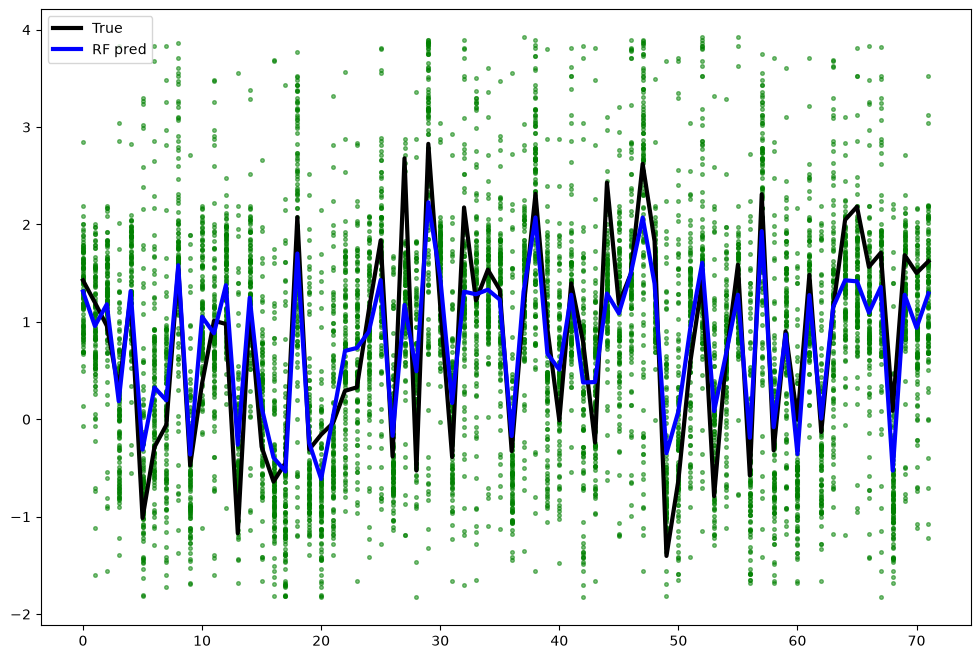

In [11]:
from sklearn.metrics import root_mean_squared_error

f,ax = plt.subplots(figsize=(12,8))
for i in range(len(rf.estimators_)):
    ax.scatter(range(len(Xv)), rf.estimators_[i].predict(Xv), s=7, c='g', alpha=.5)

ax.plot(range(len(Xv)),yv, c= '#000000', lw=3, label='True')
ax.plot(range(len(Xv)),rf.predict(Xv), c= 'b', lw=3, label='RF pred' )
plt.legend()
plt.show()


### RF: параметры и диагностика

| Параметр | Что контролирует | На что смотреть |
|---|---|---|
| `n_estimators` | Размер ансамбля | Плато качества и расходы памяти |
| `max_features` | Случайность split / корреляцию деревьев | Test/OOB error, возможный рост bias |
| `max_depth` | Сложность каждого дерева | Разрыв train–test |
| `min_samples_leaf` | Минимальный размер листа | Стабильность вероятностей и overfitting |
| `class_weight` | Веса классов в критерии | Recall/precision, не только accuracy |

In [12]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target  # единица = 100 000 долларов

print("Размер:", X.shape)

from sklearn.model_selection import (
    train_test_split,
    KFold,
    RandomizedSearchCV
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

base_model = RandomForestRegressor(oob_score=True)

base_model.fit(X_train, y_train)

predictions = base_model.predict(X_test)
pred_train = base_model.predict(X_train)

print(f"RMSE train: {round(root_mean_squared_error(y_train, pred_train),3)}")
print(f"RMSE test: {round(root_mean_squared_error(y_test, predictions),3)}")

Размер: (20640, 8)
RMSE train: 0.186
RMSE test: 0.517


## GridSearchCV vs RandomizedSearchCV

- GridSearchCV — перебирает все комбинации гиперпараметров из заданной сетки.
- RandomizedSearchCV — случайным образом выбирает заданное количество комбинаций из распределений или списков значений гиперпараметров.

RandomizedSearchCV позволяет исследовать более широкий диапазон параметров, проверяет лишь часть пространства.

In [13]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

X = housing.data
y = housing.target  # единица = 100 000 долларов

print("Размер:", X.shape)


from sklearn.model_selection import (
    KFold,
    RandomizedSearchCV
)


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE
)

rf_params = {
    "n_estimators": [ 100, 200, 250, 400, 1000],
    "max_depth": [ 10, 18, 20, 22, 30, 40, None],
    "min_samples_leaf": [1, 2, 3, 5],
    "max_features": [0.1,  0.3, 0.5, 0.7, 1.0]
}

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

rf_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
        random_state=RANDOM_STATE,
        oob_score=True,
        n_jobs=1
    ),
    param_distributions=rf_params,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    
    return_train_score=True,
    refit=True
)

rf_search.fit(X_train, y_train)


print("Best RF parameters:")
print(rf_search.best_params_)

print("Best CV RMSE:", -rf_search.best_score_)


def get_search_results(search, model_name):
    
    results = pd.DataFrame(search.cv_results_)

    cols = [
        "params",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]

    results = results[cols].copy()

    results["Train_RMSE"] = -results["mean_train_score"]
    results["CV_RMSE"] = -results["mean_test_score"]

    results["Overfit_gap"] = (
        results["CV_RMSE"] - results["Train_RMSE"]
    )

    results["Model"] = model_name

    return results.sort_values("CV_RMSE")



rf_results = get_search_results(rf_search, "Random Forest")


display(
    rf_results[
        ["params", "Train_RMSE", "CV_RMSE", "Overfit_gap"]
    ].head(10)
)

best_rf = rf_search.best_estimator_
best_rf.fit(X_train, y_train)
predictions = best_rf.predict(X_test)
print(f"RMSE test: {round(root_mean_squared_error(y_test, predictions),3)}")

Размер: (20640, 8)
Best RF parameters:
{'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': None}
Best CV RMSE: 0.49220584496918507


,params,Train_RMSE,CV_RMSE,Overfit_gap
7,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.183568,0.492206,0.308638
6,"{'n_estimators': 1000, 'min_samples_leaf': 3, ...",0.292919,0.496286,0.203367
3,"{'n_estimators': 1000, 'min_samples_leaf': 3, ...",0.288085,0.498255,0.210171
2,"{'n_estimators': 250, 'min_samples_leaf': 3, '...",0.289028,0.498975,0.209947
8,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.187599,0.504812,0.317213
1,"{'n_estimators': 400, 'min_samples_leaf': 5, '...",0.350679,0.505074,0.154396
4,"{'n_estimators': 200, 'min_samples_leaf': 5, '...",0.378365,0.509233,0.130868
0,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.197726,0.531092,0.333367
9,"{'n_estimators': 200, 'min_samples_leaf': 1, '...",0.448788,0.545053,0.096265
5,"{'n_estimators': 200, 'min_samples_leaf': 3, '...",0.387294,0.552486,0.165192


RMSE test: 0.506


### OOB score

В sklearn OOB score считается по-разному для классификации и регрессии:
- RandomForestClassifier — по умолчанию Accuracy.
- RandomForestRegressor — по умолчанию R² (коэффициент детерминации).

Что важно понимать про OOB
- OOB не требует отдельной валидационной выборки.
- Каждый объект оценивается только деревьями, которые его не видели при обучении.
- При малом количестве деревьев оценка может быть нестабильной: некоторые объекты окажутся OOB лишь для нескольких деревьев или вообще ни для одного.
- OOB не заменяет независимую тестовую выборку, особенно если по OOB подбирались гиперпараметры.
- При временной зависимости данных или наличии нескольких наблюдений одного клиента OOB может давать слишком оптимистичную оценку из-за утечки информации между связанными объектами.


In [14]:
best_rf.oob_score_

0.8199352731671924


## Важно знать

Random Forest **может переобучиться**. 

Он значительно устойчивее к переобучению, чем одиночное дерево решений, bagging не устраняет переобучение полностью.


- Может ли RF переобучиться из-за слишком глубоких деревьев? Да.
- Может ли RF переобучиться из-за слишком большого количества деревьев? Обычно нет.


Какие параметры могут приводить к переобучению?

|Параметр	| Что повышает риск переобучения |
|---|---|
|max_depth	| Слишком большая глубина |
|min_samples_leaf |	Слишком маленькое значение, например 1 |
|min_samples_split |	Слишком маленькое значение |
|max_features |	Большие значения могут увеличивать корреляцию деревьев |
|max_samples |	Большая обучающая подвыборка может увеличивать сходство деревьев |
|n_estimators |	Увеличение обычно не вызывает дополнительного переобучения |


# P.S

1. BaggingRegressor — универсальный ансамбль, в котором можно использовать практически любой регрессор. RandomForestRegressor — специализированный ансамбль деревьев решений.
2. Параметр max_features у них работает по-разному: в Bagging признаки выбираются один раз для каждого дерева, а в Random Forest — заново в каждом узле дерева.
Причем второй механизм включается в Random Forest только при max_features < 1.0.

у RandomForestRegressor значение max_features по умолчанию равно 1.0, то есть при каждом разбиении рассматриваются все признаки (случайность по умолчанию отключена).


In [46]:
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

models = {
    "Bagging": BaggingRegressor(
        estimator=DecisionTreeRegressor(),
        n_estimators=100,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "RF_all_features": RandomForestRegressor(
        n_estimators=100,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    ),

    "RF_half_features": RandomForestRegressor(
        n_estimators=100,
        max_features=0.5,
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(
        name,
        "RMSE:",
        mean_squared_error(y_test, pred) ** 0.5
    )

Bagging RMSE: 0.5159596894556789
RF_all_features RMSE: 0.5163991403784446
RF_half_features RMSE: 0.5038293657008558


In [15]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

# 1. Генерируем данные
rng = np.random.default_rng(42)

X = rng.uniform(-5, 5, size=(500, 1))
y = np.sin(X[:, 0]) + 0.3 * X[:, 0] + rng.normal(
    0, 0.3, size=500
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

# 2. Определяем базовые алгоритмы
base_models = {
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(C=10),
    "Linear Regression": LinearRegression()
}

# 3. Сравнение
results = []

for name, base_model in base_models.items():

    # Обычная модель
    base_model.fit(X_train, y_train)
    pred_base = base_model.predict(X_test)

    # Bagging над этим алгоритмом
    bagging = BaggingRegressor(
        estimator=base_model,
        n_estimators=100,
        max_samples=0.8,
        bootstrap=True,
        random_state=42,
        n_jobs=-1
    )

    bagging.fit(X_train, y_train)
    pred_bagging = bagging.predict(X_test)

    results.append({
        "Model": name,
        "RMSE_base": np.sqrt(
            mean_squared_error(y_test, pred_base)
        ),
        "RMSE_bagging": np.sqrt(
            mean_squared_error(y_test, pred_bagging)
        )
    })

results_df = pd.DataFrame(results)

results_df["Improvement_%"] = (
    (results_df["RMSE_base"] - results_df["RMSE_bagging"])
    / results_df["RMSE_base"] * 100
)

print(results_df.round(4))

               Model  RMSE_base  RMSE_bagging  Improvement_%
0      Decision Tree     0.4382        0.3477        20.6530
1                KNN     0.3230        0.3123         3.2932
2                SVR     0.3104        0.3082         0.7067
3  Linear Regression     0.7480        0.7479         0.0008


# Разные алгоритмы в один ансамбль - Voting


In [16]:
from sklearn.ensemble import VotingRegressor


ensemble = VotingRegressor(
    estimators=[
        ("tree", DecisionTreeRegressor()),
        ("knn", KNeighborsRegressor()),
        ("svr", SVR()),
        ("LR", LinearRegression())
    ]
)

ensemble.fit(X_train, y_train)
pred_voting = ensemble.predict(X_test)
print("RMSE ", root_mean_squared_error(y_test, pred_voting))

RMSE  0.3727946064542296


# Таким образом:
- Bagging — один алгоритм, много bootstrap-выборок.
- Voting — разные алгоритмы, прогнозы которых усредняются.
- Stacking — разные алгоритмы, прогнозы которых объединяются с помощью дополнительной модели.




# Boosting

Основная идея - Можно ли из множества слабых моделей построить одну сильную?


- Boosting — общий принцип последовательного объединения слабых моделей.
- Gradient Boosting — способ строить ансамбль, последовательно минимизируя функцию потерь с помощью функционального аналога градиентного спуска.


|Bagging / Random Forest |	Boosting |
|---|---|
|Модели можно обучать независимо |	Модели обучаются последовательно |
|Каждая модель решает исходную задачу |	Следующая модель учитывает текущие ошибки ансамбля |
|Усреднение снижает прежде всего variance	| Последовательные поправки могут снижать bias, но влияют и на variance |
|Легко распараллелить обучение деревьев | Последовательные итерации зависимы |
|Обычно используют глубокие деревья	| Часто используют неглубокие деревья |

## 4. Gradient Boosting

Вместо усреднения независимых деревьев строим аддитивную модель:

$$F_M(x)=F_0(x)+\eta\sum_{m=1}^{M}\ h_m(x).$$

На шаге $m$ вычисляем **псевдоостатки**:

$$r_{im}=-\left.\frac{\partial L(y_i,F(x_i))}{\partial F(x_i)}\right|_{F=F_{m-1}}.$$


- При $L=\frac12(y-F)^2$ получаем $r_{im}=y_i-F_{m-1}(x_i)$ — обычные остатки. 

- При log-loss псевдоостатки устроены иначе. Дерево $h_m$ приближает отрицательный градиент, после чего выполняется шаг в пространстве предсказательных функций. 



|Преимущества	| Недостатки |
|---|---|
|Высокое качество на многих табличных задачах	| Может переобучаться, особенно на шумных данных |
|Автоматически моделирует нелинейности и взаимодействия	| Много взаимосвязанных гиперпараметров|
|Не требует масштабирования признаков	|Последовательное обучение ограничивает параллелизм|
|Хорошо работает с числовыми и, в специальных реализациях, категориальными признаками|	Интерпретация сложнее, чем у линейных моделей|
|Позволяет контролировать сложность через глубину, learning rate, регуляризацию	| Не экстраполирует тренды так естественно, как параметрические модели|

[3.425 3.425 3.425 3.425 3.425 3.425 3.425 3.425]
F0 = 3.425
Шаг 1: residual [-2.42 -2.02 -1.62 -0.02  0.28  0.78  2.38  2.68], MSE=1.417
Шаг 2: residual [-1.41 -1.01 -0.61 -0.63 -0.33  0.17  1.77  2.07], MSE=0.497


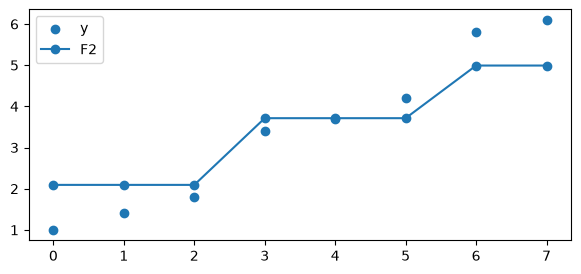

In [4]:
# Ручной GB для MSE: 1 базовое значение + 3 дерева остатков
X_demo = np.array([0, 1, 2, 3, 4, 5, 6, 7], dtype=float).reshape(-1, 1)
y_demo = np.array([1.0, 1.4, 1.8, 3.4, 3.7, 4.2, 5.8, 6.1])

eta = .5

F = np.full(len(y_demo), y_demo.mean())  # оптимальная константа при MSE

print(F)
print('F0 =',round(y_demo.mean(),3))

for m in range(1, 3):
    residual = y_demo - F            # negative gradient for 1/2 MSE
    h = DecisionTreeRegressor(max_depth=1, random_state=m).fit(X_demo,residual)
    F = F + eta*h.predict(X_demo)
    print(f'Шаг {m}: residual {np.round(residual,2)}, MSE={mean_squared_error(y_demo,F):.3f}')

plt.figure(figsize=(7,3));
plt.scatter(X_demo[:,0],y_demo,label='y');
plt.plot(X_demo[:,0],F,'o-',label=f'F{m}');
plt.legend();
plt.show()

# Важный недостаток: чувствительность к шуму

- При ошибке в метке бустинг будет последовательно пытаться исправить "ошибку" на этом наблюдении и преуспеет в этом.
Регуляризация, ограничение глубины, размер листьев и early stopping помогают контролировать такую проблему.



### Early stopping и диагностика overfitting

При увеличении числа итераций train loss обычно снижается, но validation loss может начать расти. **Early stopping** выбирает момент останова на validation; тестовую выборку нельзя использовать ни для выбора числа деревьев, ни для настройки гиперпараметров.

Два основных варианта:
1. Встроенный Early Stopping — через n_iter_no_change, validation_fraction и tol.
2. Ручной Early Stopping — через staged_predict(), если мы хотим самостоятельно выбрать метрику, например RMSE, MAE, ROC AUC.

|Параметр	|Значение|
|---|---|
|n_estimators=1000	|Максимальное количество итераций бустинга|
|n_iter_no_change=20	|Остановка, если за последние 20 итераций не было достаточного улучшения|
|validation_fraction=0.2	|20% обучающей выборки резервируется для валидации|
|tol=1e-4	|Минимальное улучшение, которое считается значимым|
|random_state=42	|Фиксирует случайное разбиение и другие случайные операции|

#### **gb.staged_predict** позволяет получить предсказания модели после каждой итерации бустинга,

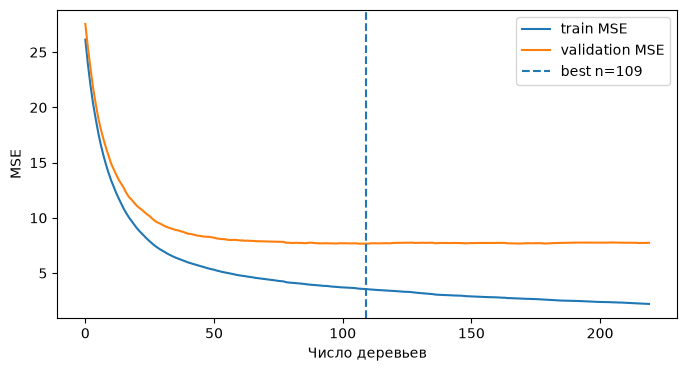

Оптимальное число деревьев в этом эксперименте: 109


In [52]:
# Train/test MSE по итерациям GB (идея early stopping)
from sklearn.datasets import make_friedman1

X_gb, y_gb = make_friedman1(n_samples=1500, n_features=10, noise=2.5, random_state=42)
X_a, X_b, y_a, y_b = train_test_split(X_gb,y_gb,test_size=.3,random_state=42)

gb = GradientBoostingRegressor(n_estimators=220, learning_rate=.1,max_depth=3,random_state=42)
gb.fit(X_a,y_a)

train_curve = [mean_squared_error(y_a,p) for p in gb.staged_predict(X_a)]
valid_curve = [mean_squared_error(y_b,p) for p in gb.staged_predict(X_b)]
best_n = int(np.argmin(valid_curve))+1

plt.figure(figsize=(8,4));
plt.plot(train_curve,label='train MSE');
plt.plot(valid_curve,label='validation MSE');
plt.axvline(best_n,linestyle='--',label=f'best n={best_n}');
plt.legend();
plt.xlabel('Число деревьев');
plt.ylabel('MSE');
plt.show()
print('Оптимальное число деревьев в этом эксперименте:',best_n)

## sklearn, XGBoost, LightGBM, CatBoost

4 библиотеки про градиентный бустинг, разные алгоритмы, регуляризация, обработка категорий и early stopping.

|Библиотека	|Модель	|Главное преимущество|
|---|---|---|
|scikit-learn	|HistGradientBoostingRegressor	|Простота и интеграция со sklearn|
|XGBoost	|XGBRegressor	|Гибкая регуляризация и настройка алгоритма| 
|LightGBM	|LGBMRegressor	| Скорость и эффективная работа с большими данными|
|CatBoost	|CatBoostRegressor	| Категориальные признаки и ordered boosting|



## XGBoost / LightGBM / CatBoost

Все три — градиентный бустинг над деревьями, но отличаются структурой дерева, оптимизацией и обработкой признаков.

| Аспект | XGBoost | LightGBM | CatBoost |
|---|---|---|---|
| Типичный рост дерева | depth-wise (есть другие режимы) | leaf-wise | symmetric / oblivious по умолчанию |
| Категориальные признаки | Native categorical (`enable_categorical=True`), либо OHE | Native categories, либо OHE | Native categories, в том числе target-statistics |
| Главный риск | Настройка сложности, overfit | Глубокие пути из-за leaf-wise роста | Время/ресурсы; настройки и режим обработки категорий |

**Не делать некорректных выводов:** один эксперимент не доказывает, что библиотека всегда лучше; одинаковое `max_depth` не означает одинаковую емкость моделей. Более того, CatBoost и LightGBM имеют разные реализации early stopping, а значения регуляризационных параметров не всегда сопоставимы.

**Отдельно:** CatBoost не делает «наивный target encoding по всей таблице». Простое вычисление target mean до train/test split — **data leakage**. 

Документация: [XGBoost: categorical features](https://xgboost.readthedocs.io/en/stable/tutorials/categorical.html), [LightGBM: features](https://lightgbm.readthedocs.io/en/stable/Features.html), [CatBoost: categorical features](https://catboost.ai/en/docs/concepts/algorithm-main-stages_cat-to-numberic).

создадим синтетический датасет банковских корпоративных клиентов для задачи прогнозирования торгового оборота клиента на следующий месяц.

Создаётся 12 000 наблюдений с пятью признаками.

|Признак	|Описание	|Генерация|
|---|---|---|
|previous_turnover|	Оборот клиента за предыдущий период	|Логнормальное распределение|
|active_days|	Количество активных торговых дней	|От 1 до 22|
|client_age_months	|Сколько месяцев клиент обслуживается в банке	|От 1 до 119|
|sector	|Отрасль клиента	|Розница, промышленность, услуги, строительство|
|segment	|Размер клиентского бизнеса |	Малый, средний, крупный|
|next_month_turnover	|Оборот в следующем месяце — целевая переменная|	Рассчитывается по нелинейной формуле с шумом|

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
n = 12000

df = pd.DataFrame({
    "previous_turnover": rng.lognormal(12, 1.0, n),
    "active_days": rng.integers(1, 23, n),
    "client_age_months": rng.integers(1, 120, n),
    "sector": rng.choice(
        ["retail", "industry", "services", "construction"],
        size=n
    ),
    "segment": rng.choice(
        ["small", "medium", "large"],
        size=n
    )
})

sector_effect = df["sector"].map({
    "retail": 1.15,
    "industry": 1.40,
    "services": 0.90,
    "construction": 1.10
})

segment_effect = df["segment"].map({
    "small": 0.80,
    "medium": 1.00,
    "large": 1.35
})

# Нелинейная зависимость с взаимодействиями
signal = (
    df["previous_turnover"]
    * (0.35 + 0.025 * df["active_days"])
    * sector_effect
    * segment_effect
    + 15000 * np.log1p(df["client_age_months"])
)

# Мультипликативный шум
df["next_month_turnover"] = signal * rng.lognormal(
    mean=0, sigma=0.25, size=n
)

X = df.drop(columns="next_month_turnover")
y = df["next_month_turnover"]

cat_cols = ["sector", "segment"]

# 60% train / 20% validation / 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=RANDOM_STATE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE
)

for part in [X_train, X_val, X_test]:
    for col in cat_cols:
        part[col] = pd.Categorical(
            part[col],
            categories=X_train[col].unique()
        )
X

,previous_turnover,active_days,client_age_months,sector,segment
0,1.011309e+06,20,55,services,large
1,7.492577e+03,2,24,construction,large
2,4.242440e+05,9,112,industry,small
3,1.744925e+05,22,87,construction,large
4,6.081945e+05,13,27,construction,medium
...,...,...,...,...,...
11995,2.522215e+04,13,95,construction,medium
11996,1.430258e+05,9,13,construction,large
11997,2.158074e+05,2,61,services,medium
11998,2.174314e+05,13,21,retail,small


## Sklearn

- GradientBoostingRegressor — классический алгоритм, удобный для изучения;
- HistGradientBoostingRegressor — более современный и эффективный вариант на основе гистограмм.


Этот вариант использует передачу внешней validation-выборки

Преимущества: гистограммное ускорение, поддержка NaN, категориальных признаков, monotonic constraints и interaction constraints.
Модель хорошо интегрируется с Pipeline, cross_validate и GridSearchCV.

Ограничения: возможности настройки обучения и специализированных функций потерь менее обширны, чем у специализированных библиотек. Количество категорий в одном признаке ограничено max_bins, поэтому high-cardinality категории требуют отдельного подхода. 

In [21]:
from sklearn.ensemble import HistGradientBoostingRegressor

sk_model = HistGradientBoostingRegressor(
    loss="squared_error",
    learning_rate=0.05,
    max_iter=1000,
    max_leaf_nodes=31,
    max_depth=5,
    min_samples_leaf=20,
    l2_regularization=1.0,
    categorical_features="from_dtype",
    early_stopping=True,
    n_iter_no_change=50,
    random_state=RANDOM_STATE
)

sk_model.fit(
    X_train, y_train,
    X_val=X_val,
    y_val=y_val
)

print("Iterations:", sk_model.n_iter_)

sk_pred = sk_model.predict(X_test)

Iterations: 194


# XGBoost


Ключевое отличие XGBoost — явная регуляризация сложности деревьев и использование информации о первой и второй производных функции потерь.


|Параметр	|Что делает|
|---|---|
|gamma	|Минимальное улучшение целевой функции, необходимое для разбиения|
|min_child_weight	|Минимальная сумма гессианов в дочернем узле|
|reg_lambda	|L2-регуляризация весов листьев|
|reg_alpha	|L1-регуляризация весов листьев|
|subsample	|Случайная доля наблюдений|
|colsample_bytree	|Случайная доля признаков для дерева|
|tree_method="hist"	|Гистограммный поиск разбиений|

Особенно важно не путать min_child_weight и min_samples_leaf.

В XGBoost min_child_weight — это не минимальное количество наблюдений, а минимальная сумма вторых производных loss. Для MSE с определённой нормировкой это связано с размером листа, но для LogLoss величина зависит и от вероятностей, прогнозируемых моделью.

In [22]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    objective="reg:squarederror",
    eval_metric="rmse",

    n_estimators=1000,
    learning_rate=0.05,
    max_depth=5,

    min_child_weight=5,
    gamma=0.0,

    subsample=0.8,
    colsample_bytree=0.8,

    reg_alpha=0.0,
    reg_lambda=1.0,

    tree_method="hist",
    enable_categorical=True,

    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_train, y_train), (X_val, y_val)],
    verbose=False
)

print("Best iteration:", xgb_model.best_iteration)
print("Best score:", xgb_model.best_score)

xgb_pred = xgb_model.predict(X_test)

Best iteration: 162
Best score: 141758.50201001306


### LightGBM 
 Эффективное обучение на больших табличных выборках.

In [23]:
from lightgbm import LGBMRegressor
import lightgbm as lgb

lgb_model = LGBMRegressor(
    objective="regression",
    n_estimators=1000,
    learning_rate=0.05,

    num_leaves=31,
    max_depth=5,
    min_child_samples=20,

    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,

    reg_alpha=0.0,
    reg_lambda=1.0,

    verbosity=-1,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    eval_metric="rmse",
    categorical_feature=cat_cols,

    callbacks=[
        lgb.early_stopping(
            stopping_rounds=50,
            verbose=False
        ),
        lgb.log_evaluation(period=0)
    ]
)

print("Best iteration:", lgb_model.best_iteration_)

lgb_pred = lgb_model.predict(X_test)

/Users/irinakharkova/my_projects/ml_course/2 семинар линейнай регрессия/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Best iteration: 324


### CatBoost (Categorical Boosting)

CatBoost может напрямую принимать строковые значения категорий.

In [24]:
from catboost import CatBoostRegressor

X_train_cb = X_train.copy()
X_val_cb = X_val.copy()
X_test_cb = X_test.copy()

for part in [X_train_cb, X_val_cb, X_test_cb]:
    part[cat_cols] = part[cat_cols].astype(str)

cb_model = CatBoostRegressor(
    loss_function="RMSE",
    eval_metric="RMSE",

    iterations=1000,
    learning_rate=0.05,
    depth=5,

    l2_leaf_reg=3.0,
    random_strength=1.0,

    cat_features=cat_cols,

    random_seed=RANDOM_STATE,
    verbose=False,
    allow_writing_files=False
)

cb_model.fit(
    X_train_cb, y_train,
    eval_set=(X_val_cb, y_val),
    early_stopping_rounds=50,
    use_best_model=True
)

print("Best iteration:", cb_model.best_iteration_)
print("Number of trees:", cb_model.tree_count_)

cb_pred = cb_model.predict(X_test_cb)

Best iteration: 205
Number of trees: 206


### Сравним качество всех 4 моделей

,Model,MAE,RMSE,R2
0,CatBoost,57469.156,105666.546,0.881
1,LightGBM,58926.548,106809.405,0.878
2,sklearn HistGB,57784.125,106870.781,0.878
3,XGBoost,58220.425,108131.400,0.875


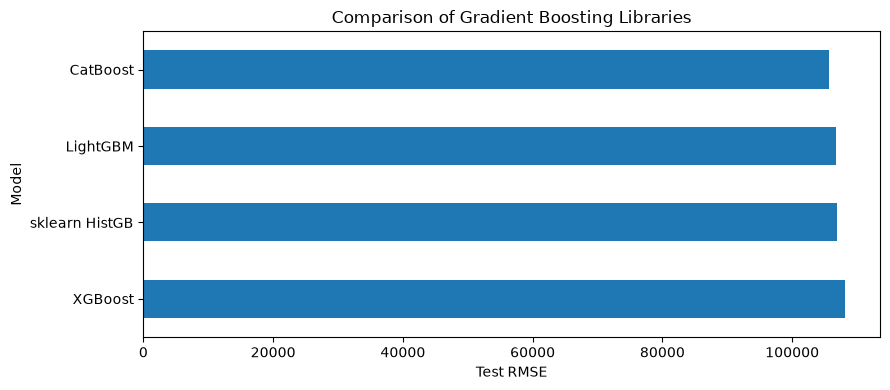

In [25]:
from sklearn.metrics import mean_absolute_error, r2_score

predictions = {
    "sklearn HistGB": sk_pred,
    "XGBoost": xgb_pred,
    "LightGBM": lgb_pred,
    "CatBoost": cb_pred
}

results = []

for name, pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "R2": r2_score(y_test, pred)
    })

results_df = (
    pd.DataFrame(results)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

display(results_df.round(3))


results_df.sort_values("RMSE", ascending=False).plot.barh(
    x="Model",
    y="RMSE",
    legend=False,
    figsize=(9, 4)
)

plt.title("Comparison of Gradient Boosting Libraries")
plt.xlabel("Test RMSE")
plt.tight_layout()
plt.show()

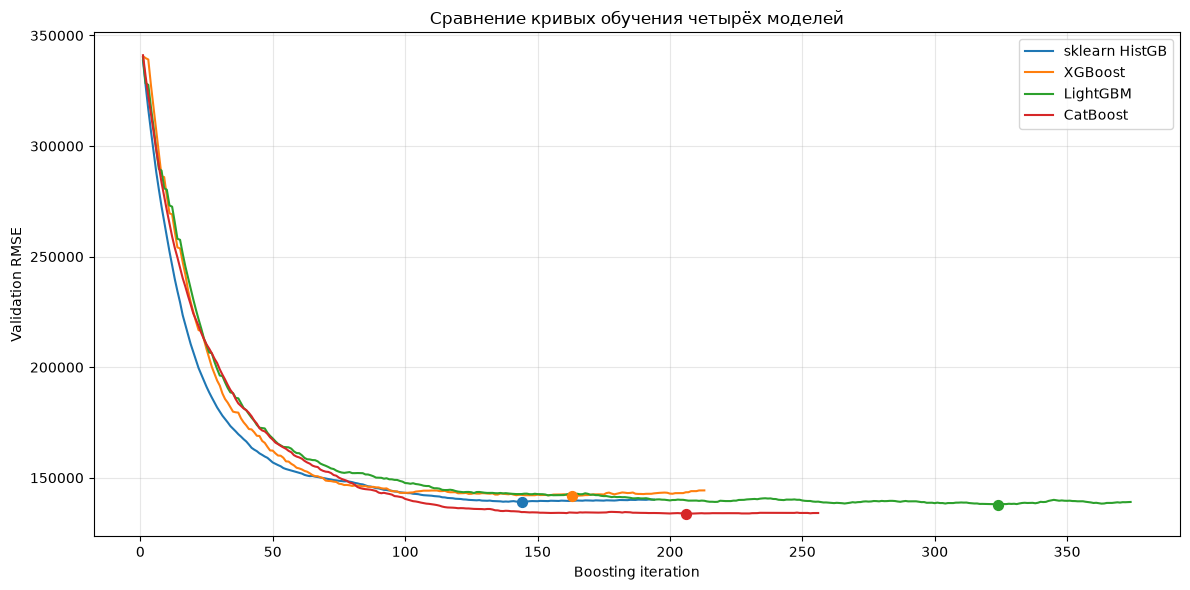

In [28]:
# Истории метрик уже обученных моделей
xgb_history = xgb_model.evals_result()
lgb_history = lgb_model.evals_result_
cb_history = cb_model.get_evals_result()

# HistGB: предсказания на validation после каждой итерации
sk_val_rmse = [
    np.sqrt(mean_squared_error(y_val, pred))
    for pred in sk_model.staged_predict(X_val)
]

curves = {
    "sklearn HistGB": sk_val_rmse,
    "XGBoost": xgb_history["validation_1"]["rmse"],
    "LightGBM": lgb_history["valid_0"]["rmse"],
    "CatBoost": cb_history["validation"]["RMSE"],
}

plt.figure(figsize=(12, 6))

for name, values in curves.items():
    iterations = np.arange(1, len(values) + 1)
    line, = plt.plot(iterations, values, label=name)

    # Отмечаем минимум Validation RMSE
    best_idx = int(np.argmin(values))
    plt.scatter(
        iterations[best_idx],
        values[best_idx],
        color=line.get_color(),
        s=50,
        zorder=3,
    )

plt.xlabel("Boosting iteration")
plt.ylabel("Validation RMSE")
plt.title("Сравнение кривых обучения четырёх моделей")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()